# Geographic maps and regional selection

Map the Outlook index and category with latitude/longitude labels and a country/state basemap. The bundled Natural Earth boundaries work offline. Plotting stride changes display density only, not the exported dataset.

In [1]:
%matplotlib inline
from pathlib import Path
import sys
ROOT = Path.cwd()
if not (ROOT / 'manifest.json').exists():
    ROOT = ROOT.parent
assert (ROOT / 'manifest.json').exists(), 'Run from the package root or notebooks folder.'
sys.path.insert(0, str(ROOT / 'examples'))
import outlook
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


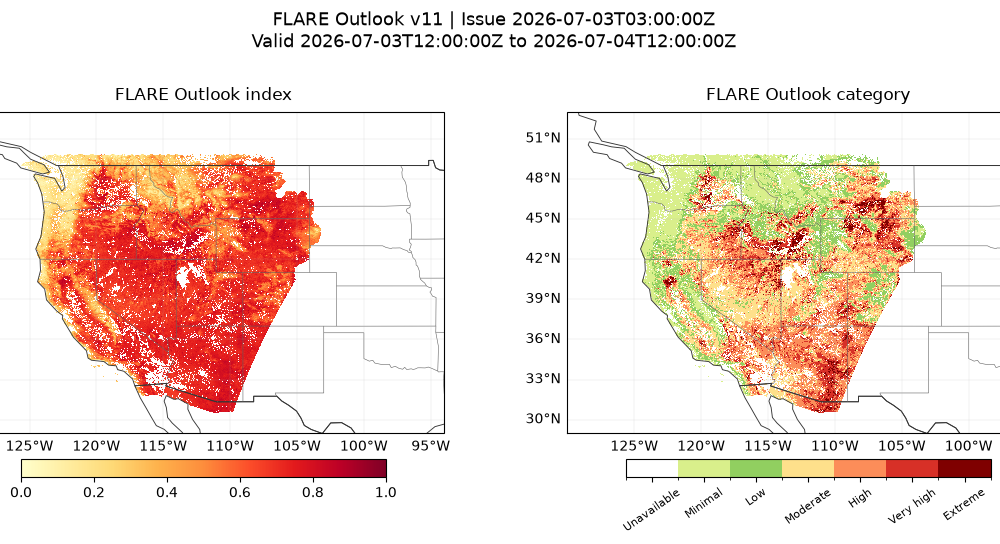

In [2]:
DATE = '2026-07-03'
STRIDE = 8  # Use 1 for every native pixel; needs more memory/rendering time.
ds = outlook.open_day(DATE)
fig = outlook.plot_maps(ds, stride=STRIDE)
plt.show()

## Select a region

Edit the bounds below. Selection uses the full 2D coordinates and preserves the native grid within the smallest covering rectangle; forecast pixels outside the bounds are masked.

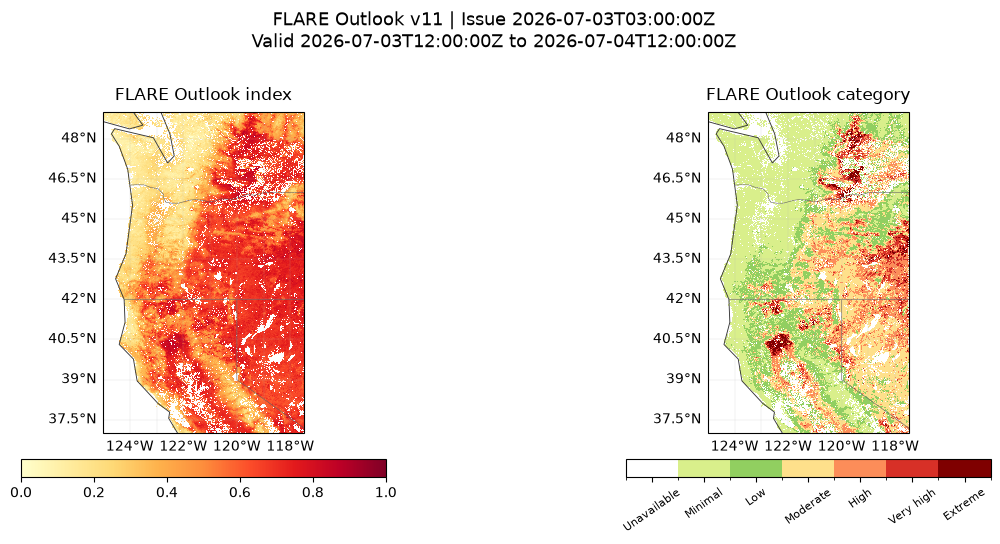

Regional native-grid shape: {'y': 3338, 'x': 3227}


In [3]:
WEST, EAST, SOUTH, NORTH = -125, -117.5, 37, 49
regional = outlook.subset_bbox(ds, WEST, EAST, SOUTH, NORTH)
fig = outlook.plot_maps(regional, stride=4, extent=(WEST, EAST, SOUTH, NORTH))
plt.show()
print('Regional native-grid shape:', dict(regional.sizes))

## Optional local export

The cell below does not write unless you set `SAVE_REGION=True`. A region is a derived subset, not a replacement for the original daily file.

In [4]:
SAVE_REGION = False
if SAVE_REGION:
    folder = ROOT / 'user_outputs'
    folder.mkdir(exist_ok=True)
    encoding = {name: {'zlib': True, 'complevel': 9, 'shuffle': True}
                for name in ['outlook_index', 'category', 'lat', 'lon']}
    regional.to_netcdf(folder / f'outlook_region_{DATE}.nc', engine='netcdf4', encoding=encoding)
ds.close()